In [1]:
import numpy as np
import pandas as pd

RUN = 2407
CHUNK_ID = 0

base = "/scratch/elena/9Li/results"
old = pd.read_pickle(f"{base}/run{RUN}/processed/Li9_clusters_chunk_{CHUNK_ID}.pkl")
dw0 = pd.read_pickle(f"{base}/test_dw_run{RUN}_0/Li9_clusters_chunk_{CHUNK_ID}.pkl")
dw5 = pd.read_pickle(f"{base}/test_dw_run{RUN}_5000/Li9_clusters_chunk_{CHUNK_ID}.pkl")

# 1) dw=0 must reproduce the old output
cols = ["t_window_start_ns", "nHits", "t_rms_ns", "spill_id"]
print("dw=0 identical to old:", len(old) == len(dw0) and old[cols].equals(dw0[cols]))

# 2) dw=5000: minimum time difference between consecutive candidates within a spill
min_dt = min(np.diff(np.sort(g["t_window_start_ns"].to_numpy())).min()
             for _, g in dw5.groupby("spill_id") if len(g) > 1)
print(f"clusters: old {len(old)} -> with death window {len(dw5)}")
print(f"min dt between consecutive candidates: {min_dt:.1f} ns (expected >= 5020)")

dw=0 identical to old: True
clusters: old 30047 -> with death window 27038
min dt between consecutive candidates: 5020.1 ns (expected >= 5020)


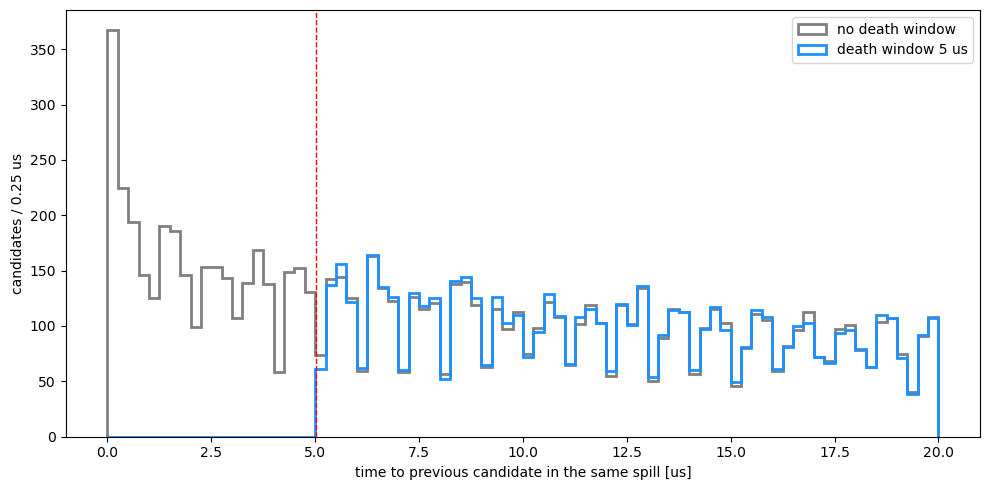

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def consecutive_dt_us(df):
    """Time to the previous candidate in the same spill, in microseconds."""
    out = []
    for _, g in df.groupby("spill_id"):
        t = np.sort(g["t_window_start_ns"].to_numpy())
        out.append(np.diff(t))
    return np.concatenate(out) * 1e-3

dt0 = consecutive_dt_us(dw0)
dt5 = consecutive_dt_us(dw5)

bins = np.linspace(0, 20, 81)   # 0.25 us bins
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(dt0, bins=bins, histtype="step", lw=2, color="gray", label="no death window")
ax.hist(dt5, bins=bins, histtype="step", lw=2, color="dodgerblue", label="death window 5 us")
ax.axvline(5.02, color="red", ls="--", lw=1)
ax.set_xlabel("time to previous candidate in the same spill [us]")
ax.set_ylabel("candidates / 0.25 us")
ax.legend()
plt.tight_layout()
plt.show()